In [1]:
# Milestone 6: consolidate every result in the project -- classical baselines, boosted-tree
# tuning, CNN-BiLSTM-Attention (pooled and un-pooled), the family-level label scheme, and
# the base-paper reproduction -- into one comparison. Every number is judged against its
# own behavior-only ceiling (the best any model can do from flow behavior alone), because
# raw scores are meaningless on this dataset without it.
import json
import sys
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Patch
from sklearn.metrics import accuracy_score, f1_score

sys.path.append(str(Path("..").resolve()))
from src.preprocessing.labels import FAMILY_MAP, FAMILY_CLASSES
from src.training.splits import behavior_keys

REPORTS = Path("../reports")
FIGURES = REPORTS / "figures"
PROCESSED = Path("../data/processed")
SEED = 2026

# Chart styling: validated reference palette (light surface), recessive solid hairline grid.
SURFACE, INK, INK2, MUTED, GRID, AXIS = "#fcfcfb", "#0b0b0b", "#52514e", "#898781", "#e1e0d9", "#c3c2b7"
BLUE, ORANGE = "#2a78d6", "#eb6834"  # categorical slots 1 and 2 (random / group split)
SEQ_BLUE = ["#cde2fb", "#9ec5f4", "#6da7ec", "#3987e5", "#256abf", "#184f95", "#0d366b"]  # sequential 100..700
SEQ_CMAP = LinearSegmentedColormap.from_list("seq_blue", SEQ_BLUE)

plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.labelcolor": INK2, "text.color": INK,
    "xtick.color": MUTED, "ytick.color": MUTED,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.axisbelow": True,
    "font.family": "sans-serif", "font.sans-serif": ["Segoe UI", "DejaVu Sans"],
    "figure.dpi": 110,
})

In [2]:
# Behavior-only ceiling: flows that are identical in every feature except ports must get
# identical predictions from any model that ignores ports, so the best such a model can do
# is give each group of identical flows the label most of them carry. Recomputed here for
# all three tasks so every ceiling quoted in the report has a reproducible source.
def behavior_ceiling(keys, labels, class_names):
    frame = pd.DataFrame({"key": np.asarray(keys), "label": np.asarray(labels).astype(str)})
    counts = frame.groupby(["key", "label"]).size().unstack(fill_value=0)
    best_guess = frame["key"].map(counts.idxmax(axis=1)).to_numpy()
    truth = frame["label"].to_numpy()

    per_class = pd.Series(
        f1_score(truth, best_guess, labels=class_names, average=None, zero_division=0), index=class_names
    )
    shared = counts.index[(counts > 0).sum(axis=1) > 1]
    summary = {
        "macro_f1": per_class.mean(),
        "accuracy": accuracy_score(truth, best_guess),
        "cross_label_share": frame["key"].isin(shared).mean(),
    }
    return summary, per_class


label_encoding = json.load(open(REPORTS / "label_encoding.json"))
class_names = sorted(label_encoding, key=label_encoding.get)

sample = pd.read_parquet(PROCESSED / "training_sample.parquet", columns=["behavior_key", "Label"])
keys = sample["behavior_key"].to_numpy()

ceil_13, ceil_13_per_class = behavior_ceiling(keys, sample["Label"], class_names)
ceil_fam, ceil_fam_per_class = behavior_ceiling(keys, sample["Label"].map(FAMILY_MAP), FAMILY_CLASSES)
n_sample = len(sample)
del sample, keys

# Base paper's 8-class subset: 03-11 capture day only, 50k rows per class (UDPLag kept
# whole), built exactly as in 04b_base_paper_reproduction.ipynb.
PAPER_CLASSES = ["BENIGN", "LDAP", "MSSQL", "NetBIOS", "Portmap", "Syn", "UDP", "UDPLag"]
candidate_features = json.load(open(REPORTS / "feature_config.json"))["numeric_feature_columns"]
behavior_cols = [c for c in candidate_features if c not in ("Source Port", "Destination Port")]

pools = {cls: [] for cls in PAPER_CLASSES}
for f in sorted((PROCESSED / "03-11").glob("*.parquet")):
    chunk = pd.read_parquet(f, columns=candidate_features + ["Label"])
    for cls in PAPER_CLASSES:
        rows = chunk.loc[chunk["Label"] == cls]
        if len(rows):
            pools[cls].append(rows)
paper = pd.concat(
    [pd.concat(parts, ignore_index=True).sample(n=min(50_000, sum(len(p) for p in parts)), random_state=SEED)
     for parts in pools.values()],
    ignore_index=True,
)
del pools, chunk

ceil_paper, ceil_paper_per_class = behavior_ceiling(
    behavior_keys(paper, behavior_cols), paper["Label"], sorted(PAPER_CLASSES)
)

ceiling_summary = pd.DataFrame([
    {"task": "13-class (attack type)", "classes": 13, "rows": n_sample, **ceil_13},
    {"task": "8-class (attack family)", "classes": 8, "rows": n_sample, **ceil_fam},
    {"task": "8-class (base-paper subset)", "classes": 8, "rows": len(paper), **ceil_paper},
]).set_index("task")
ceiling_summary.to_csv(REPORTS / "ceiling_summary.csv")
ceiling_summary.round(4)

,classes,rows,macro_f1,accuracy,cross_label_share
task,,,,,
13-class (attack type),13,3598302,0.8080,0.8091,0.6334
8-class (attack family),8,3598302,0.9661,0.9658,0.5569
8-class (base-paper subset),8,351873,0.8920,0.8874,0.4250


In [3]:
# 13-class master table: every model on the same persisted splits and features.
base = pd.read_csv(REPORTS / "baseline_results.csv").rename(columns={"protocol": "split"})
improve = pd.read_csv(REPORTS / "model_improvement_results.csv")
improve = improve[improve["model"].isin(["XGBoost_tuned", "LightGBM"])].assign(
    model=lambda d: d["model"].replace({"XGBoost_tuned": "XGBoost (tuned)"})
)
pooled = pd.read_csv(REPORTS / "hybrid_results_pooled.csv").assign(model="CNN-BiLSTM-Attention (pooled)")
unpooled = pd.read_csv(REPORTS / "hybrid_results.csv").assign(model="CNN-BiLSTM-Attention (un-pooled)")
network_v2 = pd.read_csv(REPORTS / "hybrid_v2_results.csv").assign(model="CNN-BiLSTM-Attention (log + ports)")

# Tuned decision rules (experiments/push_group_f1.py and push_f1.py): per-class log-probability offsets fitted
# on a validation slice carved out of TRAIN, so the test set stays untouched.
push_group = json.load(open(REPORTS / "push_group_f1_results.json"))
push_random = pd.read_csv(REPORTS / "push_f1_13_random.csv").set_index("model")
tuned = pd.DataFrame([
    {"split": "group", "model": "LightGBM + features + offsets", "macro_f1": push_group["LGB-eng_offsets"][0], "accuracy": push_group["LGB-eng_offsets"][1]},
    {"split": "random", "model": "LightGBM + features + offsets", "macro_f1": push_random.loc["LightGBM + eng + tuned offsets", "macro_f1"], "accuracy": push_random.loc["LightGBM + eng + tuned offsets", "accuracy"]},
    {"split": "group", "model": "Ensemble (XGBoost, LightGBM) + offsets", "macro_f1": push_group["Ensemble_offsets"][0], "accuracy": push_group["Ensemble_offsets"][1]},
    {"split": "random", "model": "Ensemble (XGBoost, LightGBM) + offsets", "macro_f1": push_random.loc["Ensemble + tuned offsets", "macro_f1"], "accuracy": push_random.loc["Ensemble + tuned offsets", "accuracy"]},
])
net_offsets = pd.read_csv(REPORTS / "hybrid_v2_offsets_results.csv")
tuned = pd.concat([tuned, pd.DataFrame({
    "split": net_offsets["split"], "model": "CNN-BiLSTM-Attention (log + ports) + offsets",
    "macro_f1": net_offsets["test_macro_f1_offsets"], "accuracy": net_offsets["test_accuracy_offsets"]})], ignore_index=True)

cols = ["split", "model", "macro_f1", "accuracy"]
long = pd.concat([base[cols + ["seconds"]], improve[cols], pooled[cols + ["seconds"]], unpooled[cols + ["seconds"]],
                  network_v2[cols + ["seconds"]], tuned[cols]], ignore_index=True)


def by_split(metric):
    return long.pivot(index="model", columns="split", values=metric).reindex(columns=["random", "group"])


macro, acc, minutes = by_split("macro_f1"), by_split("accuracy"), by_split("seconds") / 60
order = macro["random"].sort_values(ascending=False).index

master = pd.concat({
    "macro-F1": macro,
    "accuracy": acc,
    "% of ceiling (macro-F1)": macro / ceil_13["macro_f1"] * 100,
    "train+predict minutes": minutes,
}, axis=1).loc[order]

flat = master.copy()
flat.columns = [f"{a} | {b}" for a, b in flat.columns]
flat.to_csv(REPORTS / "final_summary_13class.csv")

print(f"13-class behavior-only ceiling: macro-F1 {ceil_13['macro_f1']:.4f}, accuracy {ceil_13['accuracy']:.4f} "
      f"({100 * ceil_13['cross_label_share']:.1f}% of flows share their exact behavior with another label)")
print("NaN = not run (boosted-tree tuning only completed the random split; CatBoost was abandoned as too slow on CPU)")
master.round(3)

13-class behavior-only ceiling: macro-F1 0.8080, accuracy 0.8091 (63.3% of flows share their exact behavior with another label)
NaN = not run (boosted-tree tuning only completed the random split; CatBoost was abandoned as too slow on CPU)


macro-F1        accuracy         \
split                                          random  group   random  group   
model                                                                          
LightGBM + features + offsets                   0.795  0.792    0.792  0.807   
Ensemble (XGBoost, LightGBM) + offsets          0.795  0.790    0.792  0.806   
LightGBM                                        0.794    NaN    0.790    NaN   
XGBoost                                         0.791  0.783    0.787  0.802   
XGBoost (tuned)                                 0.790    NaN    0.786    NaN   
RandomForest                                    0.781  0.758    0.775  0.780   
CNN-BiLSTM-Attention (log + ports) + offsets    0.777  0.748    0.775  0.774   
CNN-BiLSTM-Attention (log + ports)              0.770  0.744    0.767  0.768   
XGBoost (no ports)                              0.765  0.760    0.761  0.775   
CNN-BiLSTM-Attention (un-pooled)                0.705  0.690    0.714  0.718   
CNN-BiLSTM-Attention (pooled)                   0.682  0.702    0.698  0.726   
LogisticRegression                              0.676  0.686    0.664  0.697   

                                             % of ceiling (macro-F1)          \
split                                                         random   group   
model                                                                          
LightGBM + features + offsets                                 98.342  98.039   
Ensemble (XGBoost, LightGBM) + offsets                        98.342  97.799   
LightGBM                                                      98.268     NaN   
XGBoost                                                       97.859  96.878   
XGBoost (tuned)                                               97.810     NaN   
RandomForest                                                  96.643  93.778   
CNN-BiLSTM-Attention (log + ports) + offsets                  96.189  92.525   
CNN-BiLSTM-Attention (log + ports)                            95.308  92.117   
XGBoost (no ports)                                            94.654  94.012   
CNN-BiLSTM-Attention (un-pooled)                              87.253  85.395   
CNN-BiLSTM-Attention (pooled)                                 84.433  86.885   
LogisticRegression                                            83.623  84.903   

                                             train+predict minutes           
split                                                       random    group  
model                                                                        
LightGBM + features + offsets                                  NaN      NaN  
Ensemble (XGBoost, LightGBM) + offsets                         NaN      NaN  
LightGBM                                                       NaN      NaN  
XGBoost                                                     10.480   12.362  
XGBoost (tuned)                                                NaN      NaN  
RandomForest                                                 1.260    1.465  
CNN-BiLSTM-Attention (log + ports) + offsets                   NaN      NaN  
CNN-BiLSTM-Attention (log + ports)                          76.222  117.000  
XGBoost (no ports)                                          10.823   12.210  
CNN-BiLSTM-Attention (un-pooled)                            73.722   78.543  
CNN-BiLSTM-Attention (pooled)                               15.825   29.230  
LogisticRegression                                           1.782    1.683

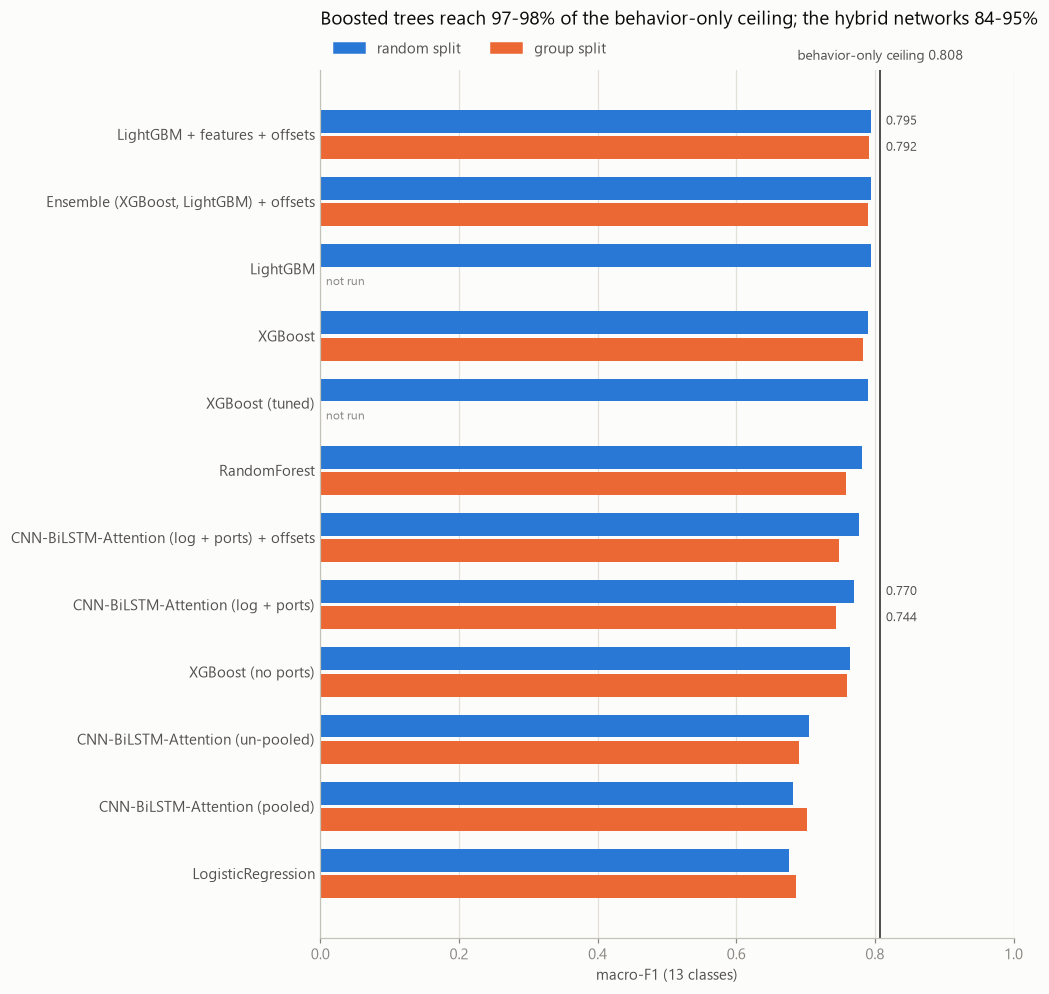

In [4]:
def label_x(value, ceiling, text_width):
    """Right of a bar's end, or right of the ceiling line if the line would cut through the label."""
    x = value + 0.008
    return ceiling + 0.008 if x < ceiling < x + text_width else x


def grouped_hbar(frame, ceiling, xlabel, title, path, label_rows=()):
    """Horizontal bars, one group per model, random (upper) vs group (lower). Bars start at zero."""
    models = list(frame.index)[::-1]  # best model on top
    y = np.arange(len(models))
    h, gap = 0.34, 0.05
    fig, ax = plt.subplots(figsize=(9.5, 0.62 * len(models) + 1.7))

    for offset, split, color in [((h + gap) / 2, "random", BLUE), (-(h + gap) / 2, "group", ORANGE)]:
        for yi, model in zip(y, models):
            v = frame.loc[model, split]
            if pd.isna(v):
                ax.text(0.008, yi + offset, "not run", va="center", fontsize=8, color=MUTED)
                continue
            ax.barh(yi + offset, v, height=h, color=color)
            if model in label_rows:
                ax.text(label_x(v, ceiling, 0.06), yi + offset, f"{v:.3f}", va="center", fontsize=8.5, color=INK2)

    ax.axvline(ceiling, color=INK2, lw=1.3)
    ax.annotate(f"behavior-only ceiling {ceiling:.3f}", xy=(ceiling, 1.0), xycoords=("data", "axes fraction"),
                xytext=(0, 5), textcoords="offset points", ha="center", va="bottom", fontsize=9, color=INK2)

    ax.set_yticks(y)
    ax.set_yticklabels(models, color=INK2, fontsize=9.5)
    ax.set_xlim(0, 1.0)
    ax.set_xlabel(xlabel)
    ax.grid(axis="y", visible=False)
    ax.tick_params(axis="y", length=0)
    ax.set_title(title, loc="left", pad=30, fontsize=12.5)
    ax.legend(handles=[Patch(color=BLUE, label="random split"), Patch(color=ORANGE, label="group split")],
              loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, labelcolor=INK2)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


pct = macro / ceil_13["macro_f1"] * 100
trees = ["XGBoost", "XGBoost (tuned)", "LightGBM"]
hybrids = ["CNN-BiLSTM-Attention (pooled)", "CNN-BiLSTM-Attention (un-pooled)", "CNN-BiLSTM-Attention (log + ports)"]
title_13 = (f"Boosted trees reach {pct.loc[trees].min().min():.0f}-{pct.loc[trees].max().max():.0f}% of the "
            f"behavior-only ceiling; the hybrid networks {pct.loc[hybrids].min().min():.0f}-{pct.loc[hybrids].max().max():.0f}%")

grouped_hbar(
    macro.loc[order], ceil_13["macro_f1"], "macro-F1 (13 classes)", title_13,
    FIGURES / "final_13class_macro_f1.png",
    label_rows=(order[0], "CNN-BiLSTM-Attention (log + ports)"),
)

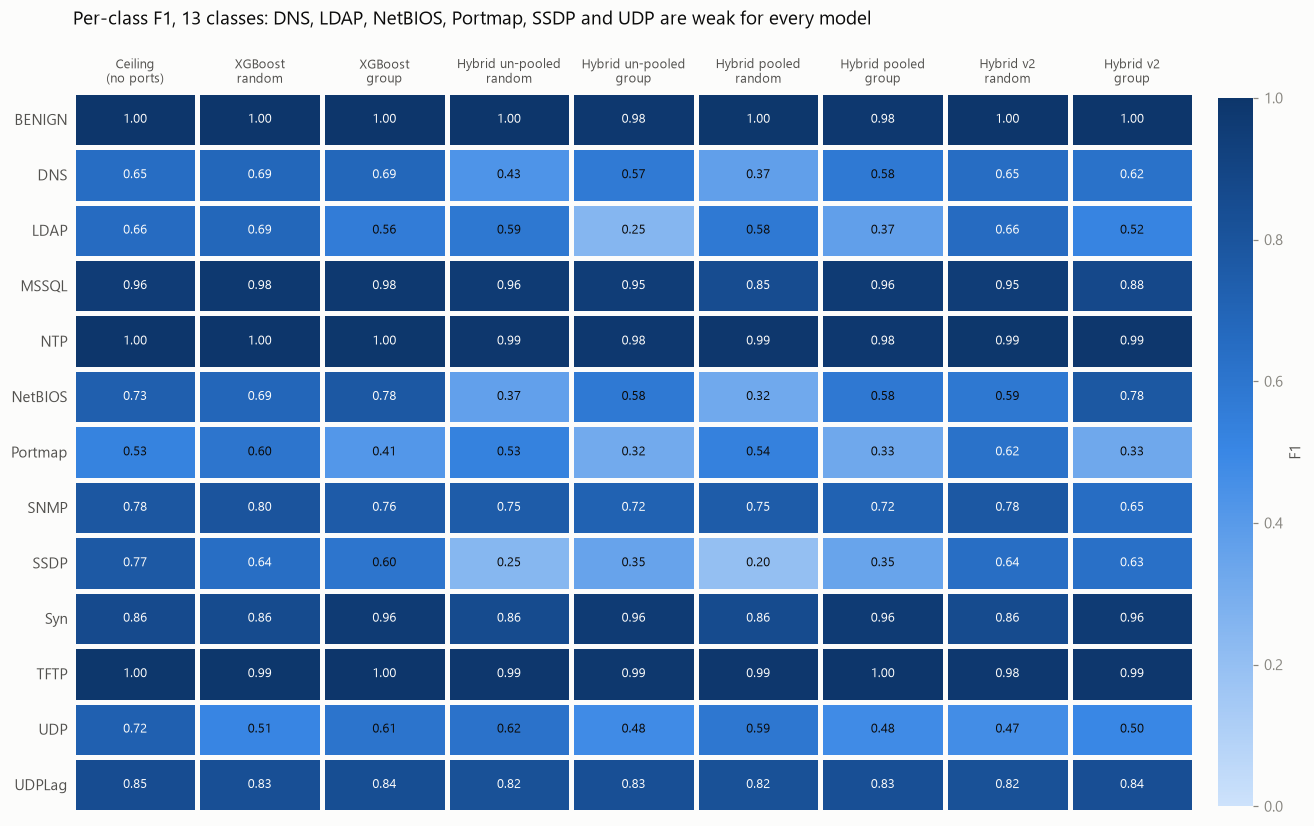

In [5]:
def f1_heatmap(table, title, path):
    """Per-class F1 as a grid (sequential, one hue). Cell values are printed, so the
    figure doubles as its own table view."""
    values = table.to_numpy(dtype=float)
    n_rows, n_cols = values.shape
    fig, ax = plt.subplots(figsize=(1.05 * n_cols + 2.6, 0.43 * n_rows + 2.0))
    mesh = ax.pcolormesh(values, cmap=SEQ_CMAP, vmin=0, vmax=1, edgecolors=SURFACE, linewidth=2)
    for i in range(n_rows):
        for j in range(n_cols):
            ax.text(j + 0.5, i + 0.5, f"{values[i, j]:.2f}", ha="center", va="center", fontsize=8.5,
                    color=SURFACE if values[i, j] > 0.62 else INK)
    ax.set_xlim(0, n_cols)
    ax.set_ylim(n_rows, 0)
    ax.set_xticks(np.arange(n_cols) + 0.5)
    ax.set_xticklabels([c.replace(" | ", "\n") for c in table.columns], fontsize=8.5, color=INK2)
    ax.set_yticks(np.arange(n_rows) + 0.5)
    ax.set_yticklabels(table.index, fontsize=9.5, color=INK2)
    ax.xaxis.tick_top()
    ax.tick_params(length=0)
    ax.grid(False)
    for spine in ax.spines.values():
        spine.set_visible(False)
    cbar = fig.colorbar(mesh, ax=ax, fraction=0.03, pad=0.02)
    cbar.outline.set_visible(False)
    cbar.set_label("F1", color=INK2)
    ax.set_title(title, loc="left", pad=44, fontsize=12.5)
    fig.tight_layout()
    fig.savefig(path, dpi=150)
    plt.show()


xgb = pd.read_csv(REPORTS / "baseline_per_class_f1.csv", index_col=0)
hyb_u = pd.read_csv(REPORTS / "hybrid_per_class_f1.csv", index_col=0)
hyb_p = pd.read_csv(REPORTS / "hybrid_per_class_f1_pooled.csv", index_col=0)

hyb_v2 = pd.read_csv(REPORTS / "hybrid_v2_per_class_f1.csv", index_col=0)

per_class_13 = pd.DataFrame({
    "Ceiling | (no ports)": ceil_13_per_class,
    "XGBoost | random": xgb["XGBoost (random)"],
    "XGBoost | group": xgb["XGBoost (group)"],
    "Hybrid un-pooled | random": hyb_u["CNN-BiLSTM-Attention (random)"],
    "Hybrid un-pooled | group": hyb_u["CNN-BiLSTM-Attention (group)"],
    "Hybrid pooled | random": hyb_p["CNN-BiLSTM-Attention (random)"],
    "Hybrid pooled | group": hyb_p["CNN-BiLSTM-Attention (group)"],
    "Hybrid v2 | random": hyb_v2.get("CNN-BiLSTM-Attention v2 (random)"),
    "Hybrid v2 | group": hyb_v2["CNN-BiLSTM-Attention v2 (group)"],
}).loc[class_names].dropna(axis=1, how="all")
per_class_13.to_csv(REPORTS / "final_summary_per_class_13class.csv")

f1_heatmap(per_class_13, "Per-class F1, 13 classes: DNS, LDAP, NetBIOS, Portmap, SSDP and UDP are weak for every model",
           FIGURES / "final_13class_per_class_f1.png")

A model that sees ports can exceed the no-port ceiling; it is a bound on flow behavior alone, not on the model.


,macro-F1,accuracy,ceiling macro-F1,ceiling accuracy,macro-F1 minus ceiling
split,,,,,
random,0.9559,0.9519,0.9661,0.9658,-0.0102
group,0.9748,0.9731,0.9661,0.9658,0.0088
random (ensemble + offsets),0.9699,0.9701,0.9661,0.9658,0.0038
group (ensemble + offsets),0.9821,0.9814,0.9661,0.9658,0.0160
"group (XGBoost + offsets, served)",0.9814,0.9808,0.9661,0.9658,0.0153


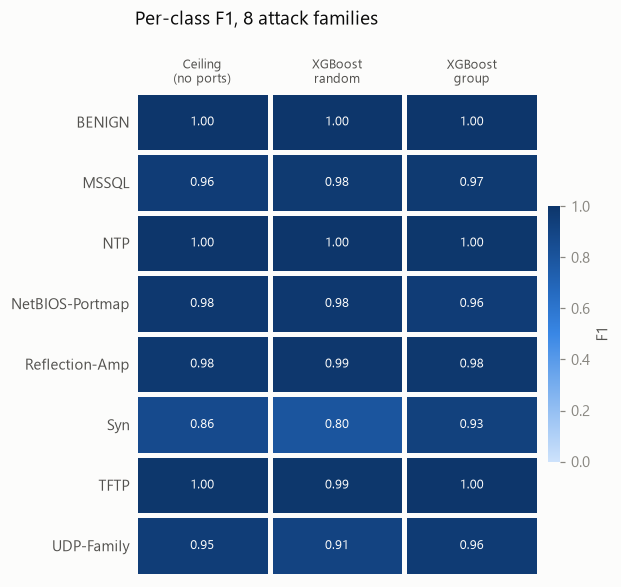

In [6]:
# Family-level label scheme (DNS/LDAP/SNMP, NetBIOS/Portmap, SSDP/UDP/UDPLag merged).
fam = pd.read_csv(REPORTS / "family_baseline_results.csv").set_index("split").loc[["random", "group"]]
fam_summary = pd.DataFrame({
    "macro-F1": fam["macro_f1"],
    "accuracy": fam["accuracy"],
    "ceiling macro-F1": ceil_fam["macro_f1"],
    "ceiling accuracy": ceil_fam["accuracy"],
    "macro-F1 minus ceiling": fam["macro_f1"] - ceil_fam["macro_f1"],
})
# Tuned decision rule (class offsets fitted on a validation slice of train). The served family model is XGBoost + offsets.
offsets_served = pd.read_csv(REPORTS / "xgb_offsets_results.csv").set_index("task").loc["family"]
push_fam = {s: pd.read_csv(REPORTS / f"push_f1_family_{s}.csv").set_index("model").loc["Ensemble + tuned offsets"] for s in ("random", "group")}
tuned_rows = {
    "random (ensemble + offsets)": (push_fam["random"]["macro_f1"], push_fam["random"]["accuracy"]),
    "group (ensemble + offsets)": (push_fam["group"]["macro_f1"], push_fam["group"]["accuracy"]),
    "group (XGBoost + offsets, served)": (offsets_served["test_macro_f1_offsets"], offsets_served["test_accuracy_offsets"]),
}
extra = pd.DataFrame({
    name: {"macro-F1": f1, "accuracy": acc, "ceiling macro-F1": ceil_fam["macro_f1"], "ceiling accuracy": ceil_fam["accuracy"],
           "macro-F1 minus ceiling": f1 - ceil_fam["macro_f1"]}
    for name, (f1, acc) in tuned_rows.items()
}).T
fam_summary = pd.concat([fam_summary, extra])
fam_summary.index.name = "split"
fam_summary.to_csv(REPORTS / "final_summary_family.csv")

fam_f1 = pd.read_csv(REPORTS / "family_baseline_per_class_f1.csv", index_col=0)
assert np.allclose(fam_f1["ceiling"], ceil_fam_per_class.loc[fam_f1.index], atol=2e-3), \
    "persisted family ceiling disagrees with the recomputed one"

per_class_fam = pd.DataFrame({
    "Ceiling | (no ports)": ceil_fam_per_class,
    "XGBoost | random": fam_f1["XGBoost (family, random)"],
    "XGBoost | group": fam_f1["XGBoost (family, group)"],
}).loc[FAMILY_CLASSES]

print("A model that sees ports can exceed the no-port ceiling; it is a bound on flow behavior alone, not on the model.")
display(fam_summary.round(4))
f1_heatmap(per_class_fam, "Per-class F1, 8 attack families",
           FIGURES / "final_family_per_class_f1.png")

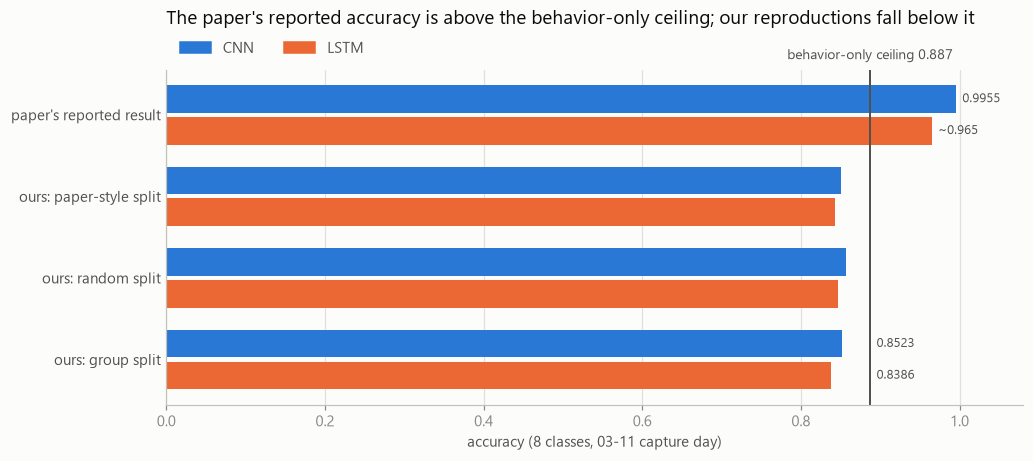

,split,model,accuracy,macro_f1,ceiling accuracy,ceiling macro-F1
0,paper's reported result,CNN,0.9955,NaN,0.8874,0.892
1,paper's reported result,LSTM,0.9650,NaN,0.8874,0.892
2,ours: paper-style split,CNN,0.8504,0.8116,0.8874,0.892
3,ours: paper-style split,LSTM,0.8425,0.7545,0.8874,0.892
4,ours: random split,CNN,0.8564,0.8294,0.8874,0.892
5,ours: random split,LSTM,0.8469,0.7946,0.8874,0.892
6,ours: group split,CNN,0.8523,0.8168,0.8874,0.892
7,ours: group split,LSTM,0.8386,0.7532,0.8874,0.892


In [7]:
# Base-paper claim vs our reproduction vs the ceiling. The claimed values are the paper's own
# Section 6 / Table 5 results (Fu et al. 2025): CNN 99.55% on all four metrics, LSTM ~96.5%.
claimed = pd.DataFrame([
    {"split": "paper's reported result", "model": "CNN", "accuracy": 0.9955, "macro_f1": np.nan},
    {"split": "paper's reported result", "model": "LSTM", "accuracy": 0.965, "macro_f1": np.nan},
])
repro = pd.read_csv(REPORTS / "base_paper_reproduction.csv")
repro["split"] = repro["split"].replace({"paper (trailing 20%)": "ours: paper-style split",
                                         "random": "ours: random split", "group": "ours: group split"})
paper_table = pd.concat([claimed, repro[["split", "model", "accuracy", "macro_f1"]]], ignore_index=True)
paper_table["ceiling accuracy"] = ceil_paper["accuracy"]
paper_table["ceiling macro-F1"] = ceil_paper["macro_f1"]
paper_table.to_csv(REPORTS / "final_summary_base_paper.csv", index=False)

acc_pivot = paper_table.pivot(index="split", columns="model", values="accuracy")
protocols = ["paper's reported result", "ours: paper-style split", "ours: random split", "ours: group split"]
acc_pivot = acc_pivot.loc[protocols]

fig, ax = plt.subplots(figsize=(9.5, 4.3))
y = np.arange(len(protocols))[::-1]
h, gap = 0.34, 0.05
ceiling_acc = ceil_paper["accuracy"]
for offset, model, color in [((h + gap) / 2, "CNN", BLUE), (-(h + gap) / 2, "LSTM", ORANGE)]:
    vals = acc_pivot[model].to_numpy()
    ax.barh(y + offset, vals, height=h, color=color)
    for yi, v, p in zip(y, vals, protocols):
        if p in ("paper's reported result", "ours: group split"):
            text = f"{v:.4f}" if not (p == "paper's reported result" and model == "LSTM") else f"~{v:.3f}"
            ax.text(label_x(v, ceiling_acc, 0.075), yi + offset, text, va="center", fontsize=8.5, color=INK2)

ax.axvline(ceiling_acc, color=INK2, lw=1.3)
ax.annotate(f"behavior-only ceiling {ceiling_acc:.3f}", xy=(ceiling_acc, 1.0),
            xycoords=("data", "axes fraction"), xytext=(0, 5), textcoords="offset points",
            ha="center", va="bottom", fontsize=9, color=INK2)
ax.set_yticks(y)
ax.set_yticklabels(protocols, color=INK2, fontsize=9.5)
ax.set_xlim(0, 1.08)
ax.set_xlabel("accuracy (8 classes, 03-11 capture day)")
ax.grid(axis="y", visible=False)
ax.tick_params(axis="y", length=0)
ax.set_title("The paper's reported accuracy is above the behavior-only ceiling; our reproductions fall below it",
             loc="left", pad=30, fontsize=12.5)
ax.legend(handles=[Patch(color=BLUE, label="CNN"), Patch(color=ORANGE, label="LSTM")],
          loc="lower left", bbox_to_anchor=(0, 1.0), ncol=2, frameon=False, labelcolor=INK2)
fig.tight_layout()
fig.savefig(FIGURES / "final_base_paper_gap.png", dpi=150)
plt.show()

paper_table.round(4)

In [8]:
# Headline findings, computed from the tables above so the report text can quote them directly.
best = order[0]
hy = "CNN-BiLSTM-Attention (un-pooled)"
hp = "CNN-BiLSTM-Attention (pooled)"
xg = "XGBoost"

print("13-CLASS TASK")
print(f"  ceiling: macro-F1 {ceil_13['macro_f1']:.3f}, accuracy {ceil_13['accuracy']:.3f}")
print(f"  best model by random macro-F1: {best} = {macro.loc[best, 'random']:.3f} "
      f"({100 * macro.loc[best, 'random'] / ceil_13['macro_f1']:.1f}% of ceiling)")
for split in ("random", "group"):
    print(f"  XGBoost {split}: {macro.loc[xg, split]:.3f} ({100 * macro.loc[xg, split] / ceil_13['macro_f1']:.1f}% of ceiling)"
          f"   proposed hybrid {split}: {macro.loc[hy, split]:.3f} ({100 * macro.loc[hy, split] / ceil_13['macro_f1']:.1f}%)"
          f"   gap {macro.loc[xg, split] - macro.loc[hy, split]:+.3f}")
d_random, d_group = macro.loc[hy, "random"] - macro.loc[hp, "random"], macro.loc[hy, "group"] - macro.loc[hp, "group"]
print(f"  removing CNN pooling: random {d_random:+.3f}, group {d_group:+.3f}  "
      f"({'opposite signs -> no consistent effect' if d_random * d_group < 0 else 'same direction on both splits'})")
print(f"  random-vs-group gap, XGBoost: {macro.loc[xg, 'random'] - macro.loc[xg, 'group']:+.3f} macro-F1")

hv = "CNN-BiLSTM-Attention (log + ports)"
for split in ("random", "group"):
    if hv in macro.index and not np.isnan(macro.loc[hv, split]):
        print(f"  network v2 {split}: {macro.loc[hv, split]:.3f} ({100 * macro.loc[hv, split] / ceil_13['macro_f1']:.1f}% of ceiling)"
              f"   gap to XGBoost {macro.loc[xg, split] - macro.loc[hv, split]:+.3f}  (v1 gap {macro.loc[xg, split] - macro.loc[hy, split]:+.3f})")

print("\n8-FAMILY TASK")
print(f"  ceiling: macro-F1 {ceil_fam['macro_f1']:.3f}, accuracy {ceil_fam['accuracy']:.3f}")
for split in ("random", "group"):
    print(f"  XGBoost {split}: macro-F1 {fam.loc[split, 'macro_f1']:.3f}, accuracy {fam.loc[split, 'accuracy']:.3f}")

print("\nBASE-PAPER 8-CLASS REPRODUCTION")
best_repro = repro.loc[repro["model"] == "CNN", "accuracy"].max()
print(f"  paper reports CNN accuracy 0.9955; ours at best {best_repro:.3f}; behavior-only ceiling {ceil_paper['accuracy']:.3f}")
print(f"  reported accuracy exceeds the no-port behavior ceiling by {0.9955 - ceil_paper['accuracy']:.3f}; "
      f"only a model exploiting ports can pass it, and our with-ports reproduction does not")

13-CLASS TASK
  ceiling: macro-F1 0.808, accuracy 0.809
  best model by random macro-F1: LightGBM + features + offsets = 0.795 (98.3% of ceiling)
  XGBoost random: 0.791 (97.9% of ceiling)   proposed hybrid random: 0.705 (87.3%)   gap +0.086
  XGBoost group: 0.783 (96.9% of ceiling)   proposed hybrid group: 0.690 (85.4%)   gap +0.093
  removing CNN pooling: random +0.023, group -0.012  (opposite signs -> no consistent effect)
  random-vs-group gap, XGBoost: +0.008 macro-F1
  network v2 random: 0.770 (95.3% of ceiling)   gap to XGBoost +0.021  (v1 gap +0.086)
  network v2 group: 0.744 (92.1% of ceiling)   gap to XGBoost +0.038  (v1 gap +0.093)

8-FAMILY TASK
  ceiling: macro-F1 0.966, accuracy 0.966
  XGBoost random: macro-F1 0.956, accuracy 0.952
  XGBoost group: macro-F1 0.975, accuracy 0.973

BASE-PAPER 8-CLASS REPRODUCTION
  paper reports CNN accuracy 0.9955; ours at best 0.856; behavior-only ceiling 0.887
  reported accuracy exceeds the no-port behavior ceiling by 0.108; only a mod